# Coffee Shop Sales Analysis
### Python | Pandas | NumPy | Matplotlib | Seaborn

**Project objective:** Explore coffee shop sales, product performance, customer-data coverage, and pastry inventory waste for April 2019.

This notebook documents the Python analysis workflow. The interactive reporting stage is presented separately in the Power BI dashboard.

**Dataset period:** April 2019  
**Main dataset:** `converted.xlsx` (multiple related worksheets)

> **How to run:** Place the original `converted.xlsx` file in the same folder as this notebook, then run the notebook from top to bottom. If your file is stored elsewhere, update the path in the data-loading cell.

## 1. Import Libraries
Import the Python libraries used for data manipulation, numerical work, and exploratory visualizations.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

## 2. Load the Dataset
Read the nine worksheets from the original Excel workbook. Each worksheet represents a different part of the business data.

In [5]:
# Keep converted.xlsx in the same folder as this notebook.
file = Path("converted.xlsx")

if not file.exists():
    raise FileNotFoundError(
        "converted.xlsx was not found. Place the original Excel dataset "
        "in the same folder as this notebook, or update the file path."
    )

In [6]:
sales = pd.read_excel(file, sheet_name="201904 sales reciepts")
customer = pd.read_excel(file, sheet_name="customer")
Dates = pd.read_excel(file, sheet_name="Dates")
generations = pd.read_excel(file, sheet_name="generations")
pastry_inventory = pd.read_excel(file, sheet_name="pastry inventory")
product = pd.read_excel(file, sheet_name="product")
sales_targets = pd.read_excel(file, sheet_name="sales targets")
sales_outlet = pd.read_excel(file, sheet_name="sales_outlet")
staff = pd.read_excel(file, sheet_name="staff")

## 3. Initial Data Exploration
Review the dimensions, data types, missing values, and exact duplicate rows in each table. This provides an initial picture of data quality before analysis.

In [7]:
tables = {
    "sales": sales,
    "customer": customer,
    "dates": Dates,
    "generations": generations,
    "pastry_inventory": pastry_inventory,
    "product": product,
    "sales_targets": sales_targets,
    "sales_outlet": sales_outlet,
    "staff": staff
}
for sheet, df in tables.items():

    print("\n", "="*50)
    print("Sheet:", sheet)
    print("Shape:", df.shape)

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:")
    print(df.duplicated().sum())


Sheet: sales
Shape: (49894, 14)

Data Types:
transaction_id               int64
transaction_date    datetime64[ns]
transaction_time            object
sales_outlet_id              int64
staff_id                     int64
customer_id                  int64
instore_yn                  object
order                        int64
line_item_id                 int64
product_id                   int64
quantity                     int64
line_item_amount           float64
unit_price                 float64
promo_item_yn               object
dtype: object

Missing Values:
transaction_id      0
transaction_date    0
transaction_time    0
sales_outlet_id     0
staff_id            0
customer_id         0
instore_yn          0
order               0
line_item_id        0
product_id          0
quantity            0
line_item_amount    0
unit_price          0
promo_item_yn       0
dtype: int64

Duplicate Rows:
0

Sheet: customer
Shape: (2246, 9)

Data Types:
customer_id                     int64
home_sto

## 4. Data Quality and Relationship Checks
### 4.1 Check reference-table keys
Check whether the expected key columns are unique in their respective lookup tables. Unique keys are important for reliable one-to-many relationships.

In [8]:
keys = {
    "customer": "customer_id",
    "product": "product_id",
    "staff": "staff_id",
    "sales_outlet": "sales_outlet_id",
    "Dates": "transaction_date",
    "generations": "birth_year"
}

for sheet, key in keys.items():

    df = pd.read_excel(file, sheet_name=sheet)

    print("\nSheet:", sheet)
    print("Key:", key)
    print("Total Rows:", len(df))
    print("Unique Values:", df[key].nunique())
    print("Duplicate Keys:", df[key].duplicated().sum())


Sheet: customer
Key: customer_id
Total Rows: 2246
Unique Values: 2246
Duplicate Keys: 0

Sheet: product
Key: product_id
Total Rows: 88
Unique Values: 88
Duplicate Keys: 0

Sheet: staff
Key: staff_id
Total Rows: 55
Unique Values: 55
Duplicate Keys: 0

Sheet: sales_outlet
Key: sales_outlet_id
Total Rows: 9
Unique Values: 9
Duplicate Keys: 0

Sheet: Dates
Key: transaction_date
Total Rows: 30
Unique Values: 30
Duplicate Keys: 0

Sheet: generations
Key: birth_year
Total Rows: 70
Unique Values: 70
Duplicate Keys: 0


### 4.2 Check sales IDs against lookup tables
Compare IDs in the sales table with the corresponding reference tables to identify sales records that do not have a matching customer, product, staff member, or outlet record.

In [9]:
relationships = {
    "customer_id": customer["customer_id"],
    "product_id": product["product_id"],
    "staff_id": staff["staff_id"],
    "sales_outlet_id": sales_outlet["sales_outlet_id"]
}

for column, reference in relationships.items():

    missing_ids = sales.loc[
        ~sales[column].isin(reference),
        column
    ].unique()

    print(f"\n{column}")
    print("Missing IDs:", missing_ids)
    print("Count:", len(missing_ids))


customer_id
Missing IDs: [   0 5000 8000]
Count: 3

product_id
Missing IDs: []
Count: 0

staff_id
Missing IDs: []
Count: 0

sales_outlet_id
Missing IDs: []
Count: 0


### 4.3 Review unmatched customer IDs
The sales table contains customer IDs `0`, `5000`, and `8000` that do not appear in the customer table. These records should not automatically be treated as known customer profiles.

In [10]:
sales[sales['customer_id'].isin([0, 5000, 8000])]['customer_id'].value_counts()

customer_id
0       25033
8000        5
5000        4
Name: count, dtype: int64

## 5. Sales Performance Analysis
### 5.1 Overall revenue and sales by outlet
Calculate total revenue and compare revenue across outlets represented in the sales data.

In [11]:
sales['line_item_amount'].sum()

np.float64(233635.95)

In [12]:
sales.groupby('sales_outlet_id')['line_item_amount'].sum().sort_values(ascending=False)

sales_outlet_id
8    79528.25
3    77213.23
5    76894.47
Name: line_item_amount, dtype: float64

### 5.2 Product-level performance
Explore quantity and revenue by product ID, then summarize the highest-revenue products.

In [13]:
sales.groupby('product_id')['quantity'].sum().sort_values(ascending=False)

product_id
50    1558
59    1546
38    1531
54    1513
32    1506
      ... 
15      48
4       47
12      45
18      42
19      36
Name: quantity, Length: 80, dtype: int64

In [14]:
sales.groupby("product_id")["line_item_amount"].sum().sort_values(ascending=False)

product_id
61    7106.00
59    6957.00
39    6328.25
41    6056.25
55    5900.00
       ...   
18     459.90
15     444.00
14     429.60
12     402.75
19     230.40
Name: line_item_amount, Length: 80, dtype: float64

In [15]:
product_sales = sales.groupby("product_id").agg(
    total_quantity=("quantity", "sum"),
    total_revenue=("line_item_amount", "sum")
).sort_values("total_revenue", ascending=False)

product_sales.head(10)

,total_quantity,total_revenue
product_id,,
61,1496,7106.00
59,1546,6957.00
39,1489,6328.25
41,1425,6056.25
55,1475,5900.00
38,1531,5741.25
60,1458,5467.50
36,1458,5467.50
40,1455,5456.25


### 5.3 Review product lookup data and merge sales with products
Merge product attributes into the sales table using `product_id`. A left join preserves all sales rows while adding available product details.

In [16]:
product.head()

,product_id,product_group,product_category,product_type,product,product_description,unit_of_measure,current_wholesale_price,current_retail_price,tax_exempt_yn,promo_yn,new_product_yn
0,1,Whole Bean/Teas,Coffee beans,Organic Beans,Brazilian - Organic,It's like Carnival in a cup. Clean and smooth.,12 oz,14.40,18.00,Y,N,N
1,2,Whole Bean/Teas,Coffee beans,House blend Beans,Our Old Time Diner Blend,Out packed blend of beans that is reminiscent ...,12 oz,14.40,18.00,Y,N,N
2,3,Whole Bean/Teas,Coffee beans,Espresso Beans,Espresso Roast,Our house blend for a good espresso shot.,1 lb,11.80,14.75,Y,N,N
3,4,Whole Bean/Teas,Coffee beans,Espresso Beans,Primo Espresso Roast,Our primium single source of hand roasted beans.,1 lb,16.36,20.45,Y,N,N
4,5,Whole Bean/Teas,Coffee beans,Gourmet Beans,Columbian Medium Roast,A smooth cup of coffee any time of day.,1 lb,12.00,15.00,Y,N,N


In [17]:
sales_merged = pd.merge(
    sales,
    product,
    on="product_id",
    how="left"
)
print(sales_merged.shape)
sales_merged.head()

(49894, 25)


,transaction_id,transaction_date,transaction_time,sales_outlet_id,staff_id,customer_id,instore_yn,order,line_item_id,product_id,...,product_category,product_type,product,product_description,unit_of_measure,current_wholesale_price,current_retail_price,tax_exempt_yn,promo_yn,new_product_yn
0,7,2019-04-01 02:00:00,12:04:43,3,12,558,N,1,1,52,...,Tea,Brewed Chai tea,Traditional Blend Chai Rg,Sit back and think of the tropical breezes.,16 oz,0.63,2.50,Y,N,N
1,11,2019-04-01 02:00:00,15:54:39,3,17,781,N,1,1,27,...,Coffee,Organic brewed coffee,Brazilian Lg,It's like Carnival in a cup. Clean and smooth.,24 oz,0.70,3.50,Y,N,N
2,19,2019-04-01 02:00:00,14:34:59,3,17,788,Y,1,1,46,...,Tea,Brewed Green tea,Serenity Green Tea Rg,Feel the stress leaving your body.,16 oz,0.63,2.50,Y,N,N
3,32,2019-04-01 02:00:00,16:06:04,3,12,683,N,1,1,23,...,Coffee,Drip coffee,Our Old Time Diner Blend Rg,An honest cup a coffee.,16 oz,0.50,2.50,Y,N,N
4,33,2019-04-01 02:00:00,19:18:37,3,17,99,Y,1,1,34,...,Coffee,Premium brewed coffee,Jamaican Coffee River Sm,Still a front runner for good premium coffee.,8 oz,0.49,2.45,Y,N,N


In [18]:
sales_merged["hour"] = pd.to_datetime(
    sales_merged["transaction_time"],
    format="%H:%M:%S"
).dt.hour

### 5.4 Performance by product group and category
Summarize revenue and quantity by product group and product category. Calculate each product group's share of total revenue.

In [19]:
sales_merged.groupby("product_group").agg({"line_item_amount":["sum","mean"] ,"quantity":"sum" , "product_id" : "nunique"})

line_item_amount            quantity product_id
                             sum       mean      sum    nunique
product_group                                                  
Add-ons                  2768.80   1.231673     3466          4
Beverages              180571.20   4.672442    59105         41
Food                    26935.70   3.536725     7764         11
Merchandise              4574.00  18.669388      255          3
Whole Bean/Teas         18786.25  16.493635     1168         21

In [20]:
sales_merged.groupby("product_group").agg({
    'line_item_amount' : 'sum',
    'quantity' : 'sum'}
).sort_values('line_item_amount' ,ascending=False)

,line_item_amount,quantity
product_group,,
Beverages,180571.20,59105
Food,26935.70,7764
Whole Bean/Teas,18786.25,1168
Merchandise,4574.00,255
Add-ons,2768.80,3466


In [21]:
sales_merged.groupby("product_category").agg({
    'line_item_amount' : 'sum',
    'quantity' : 'sum'}
).sort_values('line_item_amount' ,ascending=False)

,line_item_amount,quantity
product_category,,
Coffee,90948.45,30058
Tea,65374.25,23199
Bakery,26935.70,7764
Drinking Chocolate,24248.50,5848
Coffee beans,13676.65,616
Branded,4574.00,255
Loose Tea,3718.70,401
Flavours,2768.80,3466
Packaged Chocolate,1390.90,151


In [22]:
total_sales = sales_merged['line_item_amount'].sum()

group_sales = sales_merged.groupby('product_group')['line_item_amount'].sum()

group_sales_percentage = (group_sales / total_sales) * 100
group_sales_percentage.sort_values(ascending=False)

product_group
Beverages          77.287421
Food               11.528919
Whole Bean/Teas     8.040822
Merchandise         1.957747
Add-ons             1.185092
Name: line_item_amount, dtype: float64

## 6. Time-Based Sales Analysis
Extract the hour from `transaction_time` and compare revenue and quantity across hours. The source `transaction_date` also contains a default time component; the actual transaction time is stored separately in `transaction_time`.

In [23]:
sales['hour'] = pd.to_datetime(sales['transaction_time'], format='%H:%M:%S').dt.hour

In [24]:
sales.groupby('hour')['line_item_amount'].sum().sort_values(ascending=False)

hour
10    29039.62
9     28265.95
8     27634.96
7     21039.49
11    15406.67
15    14044.37
16    13873.26
14    13832.58
13    13690.82
17    13565.14
12    13414.53
18    11600.68
19     9604.08
6      7059.58
20      964.09
3       194.00
2       146.60
1       118.58
5        74.60
4        66.35
Name: line_item_amount, dtype: float64

In [25]:
sales.groupby('hour')['quantity'].sum().sort_values(ascending=False)

hour
10    8756
9     8441
8     8415
7     6457
11    4708
16    4354
14    4334
15    4331
17    4282
12    4258
13    4204
18    3661
19    2895
6     2212
20     287
2       48
3       38
1       28
4       25
5       24
Name: quantity, dtype: int64

### 6.1 Product-group performance by hour
Break down sales by hour and product group. This can help describe which product groups contribute to sales at different times of day.

In [26]:
sales_merged.groupby(['hour', 'product_group']).agg({
    'quantity': 'sum',
    'line_item_amount': 'sum'
}).head(60)

quantity  line_item_amount
hour product_group                              
1    Beverages              23             66.25
     Food                    2              6.75
     Whole Bean/Teas         3             45.58
2    Add-ons                 3              2.40
     Beverages              43            137.20
     Food                    2              7.00
3    Beverages              32            104.75
     Food                    3             10.25
     Whole Bean/Teas         3             79.00
4    Add-ons                 1              0.80
     Beverages              22             58.80
     Food                    2              6.75
5    Add-ons                 2              1.60
     Beverages              20             66.00
     Food                    2              7.00
6    Add-ons               170            136.00
     Beverages            1743           5369.15
     Food                  245            857.20
     Merchandise             6             98.00
     Whole Bean/Teas        48            599.23
7    Add-ons               419            334.40
     Beverages            5123          15654.10
     Food                  757           2573.10
     Merchandise            35            680.00
     Whole Bean/Teas       123           1797.89
8    Add-ons               518            412.80
     Beverages            6727          20560.70
     Food                  965           3281.96
     Merchandise            37            732.00
     Whole Bean/Teas       168           2647.50
9    Add-ons               494            394.40
     Beverages            6725          20502.40
     Food                  997           3430.49
     Merchandise            38            634.00
     Whole Bean/Teas       187           3304.66
10   Add-ons               601            483.20
     Beverages            6908          21146.35
     Food                 1019           3500.86
     Merchandise            34            572.00
     Whole Bean/Teas       194           3337.21
11   Add-ons               163            130.40
     Beverages            3950          12066.45
     Food                  524           1845.17
     Merchandise            10            162.00
     Whole Bean/Teas        61           1202.65
12   Add-ons               144            115.20
     Beverages            3650          11079.90
     Food                  413           1419.73
     Merchandise            10            162.00
     Whole Bean/Teas        41            637.70
13   Add-ons               138            111.20
     Beverages            3579          10979.85
     Food                  422           1482.89
     Merchandise            13            274.00
     Whole Bean/Teas        52            842.88
14   Add-ons               143            113.60
     Beverages            3681          11279.70
     Food                  451           1567.58
     Merchandise            10            160.00
     Whole Bean/Teas        49            711.70

### 6.2 Products sold most often at the peak revenue hour
Inspect the products with the highest quantities at 10 AM, the hour with the highest total revenue in this dataset.

In [27]:
sales_merged.loc[sales_merged['hour'] == 10].groupby('product')['quantity'].sum().sort_values(ascending=False).head(20)

product
Latte Rg                        209
Ethiopia Lg                     200
Traditional Blend Chai Lg       198
Peppermint Rg                   196
Latte                           194
Earl Grey Lg                    191
Ethiopia Sm                     191
Brazilian Sm                    188
Traditional Blend Chai Rg       184
Morning Sunrise Chai Rg         183
Brazilian Rg                    180
Espresso shot                   180
Our Old Time Diner Blend Rg     178
Sustainably Grown Organic Rg    178
Our Old Time Diner Blend Sm     177
Morning Sunrise Chai Lg         176
Chocolate syrup                 176
Brazilian Lg                    174
Our Old Time Diner Blend Lg     174
Sugar Free Vanilla syrup        173
Name: quantity, dtype: int64

## 7. Pastry Inventory and Waste Analysis
The pastry inventory worksheet covers a subset of pastry products and outlets. It should not be interpreted as a complete inventory record for every product or every outlet.

## pastry inventory

In [28]:
pastry_inventory.head()

,sales_outlet_id,transaction_date,product_id,start_of_day,quantity_sold,waste,% waste
0,3,2019-04-01,69,18,8,10,0.56
1,3,2019-04-01,70,18,12,6,0.33
2,3,2019-04-01,71,18,8,10,0.56
3,3,2019-04-01,72,48,9,39,0.81
4,3,2019-04-01,73,18,9,9,0.50


### 7.1 Merge inventory with product details
Add product names and attributes to the pastry inventory table using `product_id`.

#### merge pastry_inventory & product

In [29]:
pastry_merged = pd.merge(
    pastry_inventory,
    product,
    on='product_id',
    how='left'
)

### 7.2 Inventory summary
Review descriptive statistics and calculate total starting inventory, recorded quantity sold, and recorded waste.

In [30]:
pastry_inventory[['quantity_sold', 'waste', '% waste']].describe()

,quantity_sold,waste,% waste
count,307.000000,307.000000,307.000000
mean,9.296417,14.657980,0.581075
std,5.440115,11.202108,0.208594
min,0.000000,0.000000,0.000000
25%,6.000000,8.000000,0.440000
50%,8.000000,11.000000,0.580000
75%,11.000000,15.000000,0.720000
max,32.000000,47.000000,0.960000


In [31]:
pastry_inventory.agg({
    'start_of_day': 'sum',
    'quantity_sold': 'sum',
    'waste': 'sum'
})

start_of_day     7386
quantity_sold    2854
waste            4500
dtype: int64

### 7.3 Waste by product
Rank products by their total recorded waste. These figures describe recorded waste; they do not establish why the waste occurred.

In [32]:
pastry_merged.groupby('product')['waste'].sum().sort_values(ascending=False)

product
Ginger Scone           2140
Almond Croissant        600
Cranberry Scone         596
Hazelnut Biscotti       585
Chocolate Croissant     579
Name: waste, dtype: int64

### 7.4 Waste by product and outlet
Compare recorded waste and starting inventory across the available products and outlets.

In [33]:
pastry_merged.groupby(['product', 'sales_outlet_id']).agg({'waste' : 'sum' , 'start_of_day' : 'sum'})

waste  start_of_day
product             sales_outlet_id                     
Almond Croissant    3                  181           324
                    5                  209           378
                    8                  210           378
Chocolate Croissant 3                  185           342
                    5                  209           378
                    8                  185           378
Cranberry Scone     3                  201           342
                    5                  215           378
                    8                  180           378
Ginger Scone        3                  717           960
                    5                  747          1008
                    8                  676          1008
Hazelnut Biscotti   3                  183           378
                    5                  210           378
                    8                  192           378

In [34]:
branch_waste = pastry_merged.groupby('sales_outlet_id').agg({
    'waste': 'sum',
    'start_of_day': 'sum'
})

branch_waste['waste_rate'] = (
    branch_waste['waste'] / branch_waste['start_of_day'] * 100
).round(2)

branch_waste.sort_values('waste_rate', ascending=False)

,waste,start_of_day,waste_rate
sales_outlet_id,,,
5,1590,2520,63.10
3,1467,2346,62.53
8,1443,2520,57.26


### 7.5 Investigate inventory balance differences
Check records where starting inventory does not equal recorded sales plus recorded waste. These differences require business context and should not be assigned an assumed cause.

In [36]:
pastry_inventory[
    pastry_inventory['start_of_day'] !=
    pastry_inventory['quantity_sold'] + pastry_inventory['waste']
]

,sales_outlet_id,transaction_date,product_id,start_of_day,quantity_sold,waste,% waste
20,3,2019-04-05,69,18,0,0,0.00
60,3,2019-04-14,72,48,8,44,0.92
80,3,2019-04-18,69,18,0,0,0.00


## 8. Exploratory Outlier Review
Use descriptive statistics and boxplots to inspect the distribution of `line_item_amount`. Statistical outliers are not automatically data errors: large values may have a valid business explanation.

The IQR filter below creates a separate exploratory dataset (`sales_cleaned`). **It does not replace the original sales table and should not be used for the main revenue results unless the unusual records are independently verified.**

In [37]:
sales['line_item_amount'].describe()

count    49894.000000
mean         4.682646
std          4.436668
min          0.000000
25%          3.000000
50%          3.750000
75%          6.000000
max        360.000000
Name: line_item_amount, dtype: float64

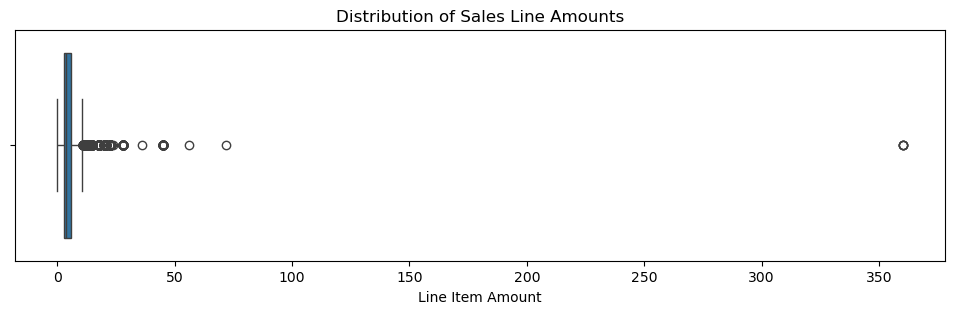

In [38]:
plt.figure(figsize=(12, 3))
sns.boxplot(x=sales["line_item_amount"])
plt.title("Distribution of Sales Line Amounts")
plt.xlabel("Line Item Amount")
plt.show()

In [39]:
sales.loc[sales['line_item_amount'] > 30, 'line_item_amount'].value_counts()

line_item_amount
45.0     63
360.0     4
36.0      1
72.0      1
56.0      1
Name: count, dtype: int64

## 9. Key Business Insights
Based on the analysis performed:

- **Total revenue:** 233,635.95.
- **Beverages:** 77.29% of total revenue.
- **Beverages and Food combined:** 88.82% of total revenue.
- **Peak revenue hour:** 10 AM.
- **Peak transaction-ID count by hour:** 11 AM (using distinct `transaction_id` values).
- **Unmatched customer ID 0:** associated with 119,312.72 in sales, or 51.07% of total revenue. This is a share of revenue, not a share of customers.
- **Recorded pastry waste:** 4,500 units out of 7,386 starting units, giving an overall recorded waste rate of 60.93%.
- **Highest recorded waste by product:** Ginger Scone, with 2,140 units (47.56% of recorded waste).
- **Highest overall recorded waste rate by outlet:** Outlet 5, at 63.10%.

## 10. Data Limitations and Interpretation

- The sales data covers April 2019 only; results should not be generalized to other months or seasons.
- Pastry inventory data covers outlets 3, 5, and 8 only, and only the pastry products included in that worksheet.
- Some sales customer IDs do not match a customer record. In particular, `customer_id = 0` is not linked to a known customer profile.
- The inventory data contains records where starting inventory differs from recorded sold plus wasted quantities. The cause is not confirmed by the available data.
- Statistical outliers were explored separately. They were not automatically treated as errors or removed from the main sales analysis.

## 11. Power BI Dashboard
The findings from this Python analysis were used to support a two-page Power BI report:

1. **Sales Overview** — key sales KPIs, product-group performance, outlet performance, hourly sales, daily sales trend, and top products.
2. **Product & Customer Analysis** — pastry waste by product and outlet, waste rates, and sales by generation and gender.

The Power BI report is provided as a separate `.pbix` file.

---
**End of notebook**